# 현실의 데이터 20: 도로 교통 속도 예측 (내비)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/20_traffic_speed.ipynb)

**분야**: 도시 · 공간 &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 내비게이션 · 도착시간 · 시공간 그래프 · 교통 관제

> 로스앤젤레스 고속도로 센서 207개. 15분 뒤 이 구간은 막힐까?

**데이터**: METR-LA (시험 기간) (약 43MB). Li et al. (2018). 로스앤젤레스 고속도로 루프 센서 207개의 5분 간격 평균 속도 (mph), 2012년 3~6월. 센서 위치 · 도로 거리로 만든 연결 그래프 포함 (Hugging Face witgaw/METR-LA, 시험 기간 2012-06-04 ~ 06-27 만 받는다).

인턴 · 산학협력 과제에서 처음 받게 될 데이터와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | 센서 × 5분 |
| ② 입력 X | 그 센서의 지난 1시간 속도 + 이웃 센서 속도 + 시각 |
| ③ 출력 y | 15분 뒤 속도 (mph) |
| ④ 평가지표 | MAE (mph), 막힘 (< 40 mph) 재현율 |
| ⑤ 기준선 | 지금 속도 그대로 |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [Li et al. (2018) Diffusion Convolutional Recurrent Neural Network: Data-Driven Traffic Forecasting, ICLR (METR-LA)](https://arxiv.org/abs/1707.01926)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

데이터가 이미 '지난 12칸 (1시간) → 다음 12칸' 창으로 잘려 있다. 필요한 열만 읽는다. 속도 0 은 '센서 고장 · 빈칸' 이다 (1주 3차시).

In [2]:
BASE = "https://huggingface.co/datasets/witgaw/METR-LA/resolve/main/"
cols = ["node_id", "t0_timestamp", "x_t+0_d1"] + [f"x_t-{k}_d0" for k in range(11, 0, -1)] + ["x_t+0_d0", "y_t+3_d0"]
df = pd.read_parquet(download(BASE + "test.parquet", "data/metrla_test.parquet"), columns=cols)
loc = pd.read_csv(download(BASE + "sensor_graph/sensor_locations.csv", "data/metrla_locations.csv"))
df["time"] = pd.to_datetime(df["t0_timestamp"])
print(df.shape, df["time"].min(), "~", df["time"].max(), "| sensors", df["node_id"].nunique())
print(f"zero (missing) speeds now: {(df['x_t+0_d0'] == 0).mean():.1%}")
loc.head(3)

(1417950, 17) 2012-06-04 04:10:00 ~ 2012-06-27 22:55:00 | sensors 207
zero (missing) speeds now: 12.1%


,sensor_id,latitude,longitude
0,773869,34.15497,-118.31829
1,767541,34.11621,-118.23799
2,767542,34.11641,-118.23819


## 열어 보기: 지도와 하루의 속도

센서 위치 (위도 · 경도) 와, 한 센서의 며칠치 속도. 출퇴근 시간에 푹 꺼질까?

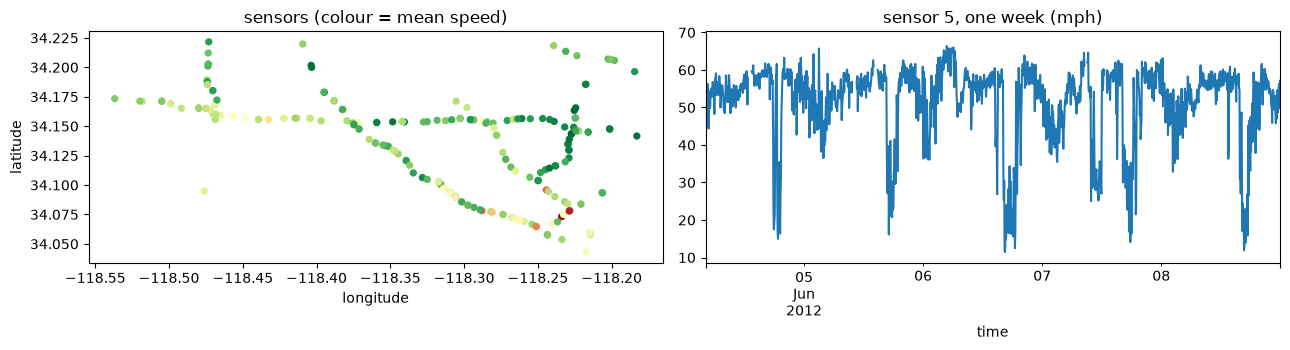

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6))
mean_speed = df[df["x_t+0_d0"] > 0].groupby("node_id")["x_t+0_d0"].mean()
axs[0].scatter(loc.iloc[:, -1], loc.iloc[:, -2], c=mean_speed.reindex(range(len(loc))).values, cmap="RdYlGn", s=18)
axs[0].set_title("sensors (colour = mean speed)"); axs[0].set_xlabel("longitude"); axs[0].set_ylabel("latitude")
one = df[df["node_id"] == 5].set_index("time")["x_t+0_d0"].replace(0, np.nan)
one[:"2012-06-08"].plot(ax=axs[1], title="sensor 5, one week (mph)")
plt.tight_layout(); plt.show()

## 문제 하나 골라 보기: 지금까지 → 15분 뒤 속도

**시간 순서**: 앞 70% 기간 학습, 뒤 30% 시험. 빈칸 (0) 인 행은 뺀다.
- 기준선: 지금 속도 그대로
- 모델 1: 그 센서의 지난 1시간 속도 12개 + 시각 → 선형회귀
- 모델 2: 모델 1 + **연결 그래프의 이웃 센서들 평균 속도** (13주차 그래프 신경망의 아이디어)

In [4]:
from sklearn.linear_model import LinearRegression

adj = np.load(download(BASE + "sensor_graph/adj_mx.npy", "data/metrla_adj.npy"), allow_pickle=True)
adj = adj[2] if adj.dtype == object else adj                  # some versions store (ids, id_map, matrix)
W = np.asarray(adj, dtype=float); np.fill_diagonal(W, 0); W = W / np.maximum(W.sum(1, keepdims=True), 1e-9)
now = df.pivot(index="time", columns="node_id", values="x_t+0_d0").replace(0, np.nan)
neigh = pd.DataFrame(np.nan_to_num(now.values) @ W.T / np.maximum((~now.isna()).values @ (W.T > 0), 1), index=now.index, columns=now.columns)
df["neigh"] = neigh.stack().reindex(pd.MultiIndex.from_arrays([df["time"], df["node_id"]])).values

lags = [f"x_t-{k}_d0" for k in range(11, 0, -1)] + ["x_t+0_d0"]
d = df[(df[lags + ["y_t+3_d0"]] > 0).all(axis=1)].copy()
cut = d["time"].quantile(0.7); tr, te = d[d["time"] <= cut], d[d["time"] > cut]
y = te["y_t+3_d0"].values; jam = y < 40
for name, cols_ in [("now", None), ("own past hour + time", lags + ["x_t+0_d1"]), ("+ neighbours", lags + ["x_t+0_d1", "neigh"])]:
    pred = te["x_t+0_d0"].values if cols_ is None else LinearRegression().fit(tr[cols_], tr["y_t+3_d0"]).predict(te[cols_])
    print(f"{name:22s} MAE {np.mean(np.abs(pred - y)):.2f} mph   jam (<40) recall {np.mean(pred[jam] < 40):.0%}")

now                    MAE 3.29 mph   jam (<40) recall 82%
own past hour + time   MAE 3.15 mph   jam (<40) recall 80%
+ neighbours           MAE 3.17 mph   jam (<40) recall 80%


**관찰**: 15분 뒤는 '지금 그대로' 가 아주 강한 기준선이다. 이웃 센서를 보면 **막힘이 앞에서부터 밀려오는 것** 을 조금 더 일찍 알아챈다. 시간이 멀수록 (1시간 뒤) 이웃 · 그래프의 도움이 커진다.

## 다른 문제로 바꿔 보기

- **도착 시간 (ETA)**: 한 행 = 출발지 → 도착지 길 하나, 출력 = 걸리는 분. 길 위 센서들의 예측 속도를 이어 붙인다.
- 사고 · 공사 같은 '이벤트' 는 과거 속도에 없다. 무엇을 입력에 더해야 할까?

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |